In [1]:
# q1 - GMM com solucao MAP (algoritmo EM)
# Levi Félix Barbosa - 579420

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from scipy.special import logsumexp

dados = np.loadtxt("clustering_data.csv", delimiter=",")
N_total, D = dados.shape
print(N_total, "pontos, D =", D)

150 pontos, D = 2


treino: 105  validacao: 45


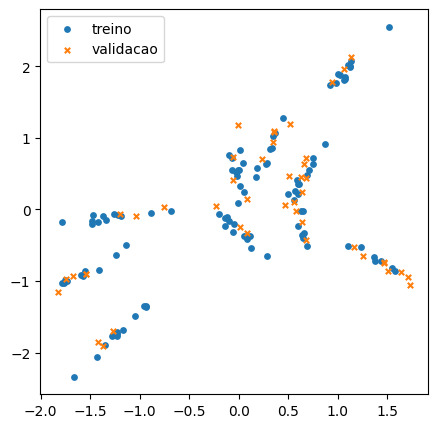

In [2]:
np.random.seed(0)
idx = np.random.permutation(N_total)
n_val = int(0.3 * N_total)
x_val = dados[idx[:n_val]]
x = dados[idx[n_val:]]
N = len(x)
print("treino:", N, " validacao:", n_val)

plt.figure(figsize=(5, 5))
plt.scatter(x[:, 0], x[:, 1], s=15, label="treino")
plt.scatter(x_val[:, 0], x_val[:, 1], s=15, marker="x", label="validacao")
plt.legend()
plt.show()

In [3]:
x_barra = x.mean(axis=0)
S_xbarra = np.cov(x.T)

def hiperparametros(K):
    alpha = np.ones(K)
    m0 = x_barra
    kappa0 = 0.01
    nu0 = D + 2
    S0 = S_xbarra / K ** (2 / D)
    return alpha, m0, kappa0, nu0, S0

In [4]:
def kmedias(x, K, n_iter=50):
    mus = [x[np.random.randint(len(x))]]
    for k in range(1, K):
        dist = np.min([np.sum((x - m) ** 2, axis=1) for m in mus], axis=0)
        mus.append(x[np.random.choice(len(x), p=dist / dist.sum())])
    mus = np.array(mus)

    for it in range(n_iter):
        dist = np.array([np.sum((x - m) ** 2, axis=1) for m in mus])
        z = np.argmin(dist, axis=0)
        for k in range(K):
            if np.sum(z == k) > 0:
                mus[k] = x[z == k].mean(axis=0)
    return mus, z

def inicializa(x, K):
    mus, z = kmedias(x, K)
    pis = np.zeros(K)
    Sigmas = np.zeros((K, D, D))
    for k in range(K):
        pis[k] = np.mean(z == k)
        if np.sum(z == k) > D:
            Sigmas[k] = np.cov(x[z == k].T) + 1e-6 * np.eye(D)
        else:
            Sigmas[k] = S_xbarra
    pis = (pis + 1e-3) / (pis + 1e-3).sum()
    return pis, mus, Sigmas

In [5]:
def log_normais(x, pis, mus, Sigmas):
    K = len(pis)
    return np.array([multivariate_normal.logpdf(x, mus[k], Sigmas[k]) for k in range(K)]).T

def log_verossimilhanca(x, pis, mus, Sigmas):
    return np.sum(logsumexp(np.log(pis) + log_normais(x, pis, mus, Sigmas), axis=1))

In [6]:
def em_map(x, K, n_iter=300, tol=1e-6):
    N = len(x)
    alpha, m0, kappa0, nu0, S0 = hiperparametros(K)
    pis, mus, Sigmas = inicializa(x, K)
    ll_antiga = -np.inf

    for t in range(1, n_iter + 1):
        # passo E
        log_r = np.log(pis) + log_normais(x, pis, mus, Sigmas)
        r = np.exp(log_r - logsumexp(log_r, axis=1, keepdims=True))

        # passo M
        Nk = r.sum(axis=0)
        pis = (alpha - 1 + Nk) / (N - K + alpha.sum())
        for k in range(K):
            x_barra_k = r[:, k] @ x / Nk[k]
            mus[k] = (kappa0 * m0 + x_barra_k * Nk[k]) / (kappa0 + Nk[k])
            dif = x - x_barra_k
            Sk = (r[:, k][:, None] * dif).T @ dif
            dm = (x_barra_k - m0)[:, None]
            Sigmas[k] = (S0 + Sk + kappa0 * Nk[k] / (kappa0 + Nk[k]) * dm @ dm.T) / (nu0 + D + 2 + Nk[k])

        ll = log_verossimilhanca(x, pis, mus, Sigmas)
        if abs(ll - ll_antiga) < tol:
            break
        ll_antiga = ll

    return pis, mus, Sigmas

In [7]:
Ks = np.arange(1, 16)
modelos = []
ll_treino, ll_val, bic, aic = [], [], [], []

for K in Ks:
    melhor, melhor_ll = None, -np.inf
    for rodada in range(5):
        params = em_map(x, K)
        ll = log_verossimilhanca(x, *params)
        if ll > melhor_ll:
            melhor, melhor_ll = params, ll

    M = (K - 1) + K * D + K * D * (D + 1) / 2
    modelos.append(melhor)
    ll_treino.append(melhor_ll)
    ll_val.append(log_verossimilhanca(x_val, *melhor))
    bic.append(melhor_ll - M / 2 * np.log(N))
    aic.append(melhor_ll - M)
    print(f"K={K:2d}  ll treino={melhor_ll:8.2f}  ll val={ll_val[-1]:8.2f}  BIC={bic[-1]:8.2f}  AIC={aic[-1]:8.2f}")

ll_treino, ll_val, bic, aic = map(np.array, (ll_treino, ll_val, bic, aic))

K= 1  ll treino= -272.35  ll val= -132.22  BIC= -283.98  AIC= -277.35
K= 2  ll treino= -243.60  ll val= -118.64  BIC= -269.20  AIC= -254.60


K= 3  ll treino= -202.81  ll val= -103.57  BIC= -242.36  AIC= -219.81


K= 4  ll treino= -176.09  ll val=  -96.71  BIC= -229.61  AIC= -199.09


K= 5  ll treino= -155.63  ll val=  -80.05  BIC= -223.11  AIC= -184.63


K= 6  ll treino= -125.99  ll val=  -74.89  BIC= -207.44  AIC= -160.99


...

K=11  ll treino=  -61.72  ll val=  -59.54  BIC= -212.97  AIC= -126.72


K=12  ll treino=  -58.51  ll val=  -59.60  BIC= -223.72  AIC= -129.51


K=13  ll treino=  -56.76  ll val=  -58.32  BIC= -235.94  AIC= -133.76


K=14  ll treino=  -52.61  ll val=  -65.88  BIC= -245.75  AIC= -135.61


K=15  ll treino=  -44.63  ll val=  -66.56  BIC= -251.73  AIC= -133.63


melhor K pelo BIC: 6
melhor K pelo AIC: 11
melhor K pela log-veross. de validacao: 13


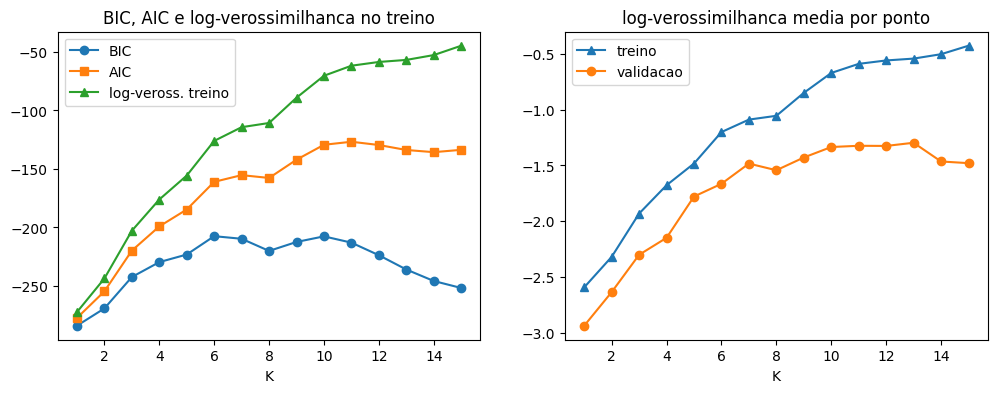

In [8]:
K_bic = Ks[np.argmax(bic)]
K_aic = Ks[np.argmax(aic)]
K_val = Ks[np.argmax(ll_val)]
print("melhor K pelo BIC:", K_bic)
print("melhor K pelo AIC:", K_aic)
print("melhor K pela log-veross. de validacao:", K_val)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(Ks, bic, "o-", label="BIC")
ax[0].plot(Ks, aic, "s-", label="AIC")
ax[0].plot(Ks, ll_treino, "^-", label="log-veross. treino")
ax[0].set_xlabel("K")
ax[0].set_title("BIC, AIC e log-verossimilhanca no treino")
ax[0].legend()

ax[1].plot(Ks, ll_treino / N, "^-", label="treino")
ax[1].plot(Ks, ll_val / n_val, "o-", label="validacao")
ax[1].set_xlabel("K")
ax[1].set_title("log-verossimilhanca media por ponto")
ax[1].legend()
plt.show()

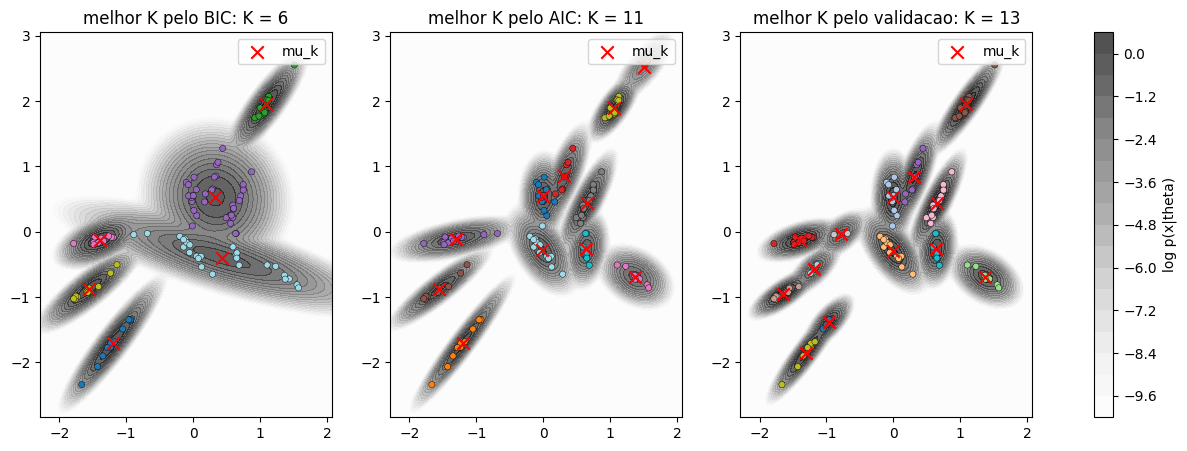

In [9]:
g1 = np.linspace(x[:, 0].min() - 0.5, x[:, 0].max() + 0.5, 150)
g2 = np.linspace(x[:, 1].min() - 0.5, x[:, 1].max() + 0.5, 150)
G1, G2 = np.meshgrid(g1, g2)
grade = np.c_[G1.ravel(), G2.ravel()]

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, (nome, K) in zip(ax, [("BIC", K_bic), ("AIC", K_aic), ("validacao", K_val)]):
    pis, mus, Sigmas = modelos[K - 1]
    log_r = np.log(pis) + log_normais(x, pis, mus, Sigmas)
    z = np.argmax(log_r, axis=1)
    log_p = logsumexp(np.log(pis) + log_normais(grade, pis, mus, Sigmas), axis=1).reshape(G1.shape)

    c = a.contourf(G1, G2, np.maximum(log_p, -10), levels=20, cmap="Greys", alpha=0.7)
    a.scatter(x[:, 0], x[:, 1], c=z, cmap="tab20", s=20, edgecolors="k", linewidths=0.3)
    a.scatter(mus[:, 0], mus[:, 1], c="red", marker="x", s=80, label="mu_k")
    a.set_title(f"melhor K pelo {nome}: K = {K}")
    a.legend()
fig.colorbar(c, ax=ax, label="log p(x|theta)")
plt.show()